In [ ]:
from sklearn._config import set_config
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

Sil scores: 32.60


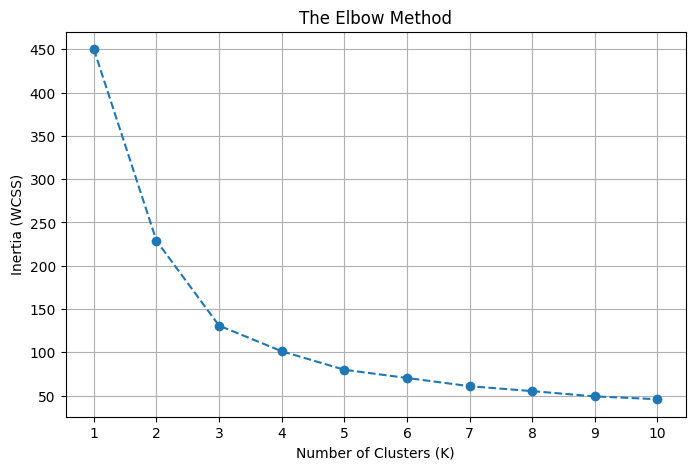

In [ ]:
set_config(transform_output="pandas")
df = pd.read_csv("Segmentation.csv")

X = df.drop(columns=["Customer_ID", "Purchase_Frequency_per_Month"])
scaled_data = StandardScaler().fit_transform(X)

model = KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(scaled_data)
labels = df["Cluster"]

# calculate the silhouette score
sil_score = silhouette_score(scaled_data, labels)

# Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), marker="o", linestyle="--")
plt.title("The Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()